## Ex 1: Dot product by hand

Multiply matching components and add the products with a plain Python loop. Compare each result with `np.dot`.

In [6]:
import numpy as np

def dot(a, b):
    if len(a) != len(b):
        raise ValueError("vectors must have the same length")

    total = 0
    for i in range(len(a)):
        total += a[i] * b[i]
    return total

examples = [
    ([3, 4], [4, 3]),
    ([1, 0], [0, 1]),
    ([1, 2, 3], [4, 5, 6]),
]

for a, b in examples:
    hand_result = dot(a, b)
    numpy_result = np.dot(a, b)
    print(f"{a} · {b} = {hand_result} (np.dot: {numpy_result})")
    assert hand_result == numpy_result

[3, 4] · [4, 3] = 24 (np.dot: 24)
[1, 0] · [0, 1] = 0 (np.dot: 0)
[1, 2, 3] · [4, 5, 6] = 32 (np.dot: 32)


## Ex 2: Norm from the dot product

The Euclidean norm is the square root of the sum of squared components. `dot(v, v)` multiplies each component by itself and sums those squares, so `norm(v) = sqrt(dot(v, v))`.

In [7]:
from math import sqrt

def norm(v):
    return sqrt(dot(v, v))

norm_examples = [[3, 4], [1, 0], [1, 2, 3]]
for v in norm_examples:
    result = norm(v)
    print(f"||{v}|| = {result} (np.linalg.norm: {np.linalg.norm(v)})")
    assert np.isclose(result, np.linalg.norm(v))



||[3, 4]|| = 5.0 (np.linalg.norm: 5.0)
||[1, 0]|| = 1.0 (np.linalg.norm: 1.0)
||[1, 2, 3]|| = 3.7416573867739413 (np.linalg.norm: 3.7416573867739413)


## Ex 3: Cosine similarity

Cosine similarity is `dot(a, b) / (norm(a) * norm(b))`. Predict these before running the code below:

- `[1, 0]` vs `[0, 1]`: 0 (orthogonal)
- `[1, 2]` vs `[2, 4]`: 1 (same direction)
- `[1, 2]` vs `[-1, -2]`: -1 (opposite directions)
- `[3, 4]` vs `[4, 3]`: 0.96 (dot product 24; both norms are 5)

In [8]:
def cosine_similarity(a, b):
    denominator = norm(a) * norm(b)
    if denominator == 0:
        raise ValueError("cosine similarity is undefined for a zero vector")
    return dot(a, b) / denominator

cosine_examples = [
    ([1, 0], [0, 1], 0.0),
    ([1, 2], [2, 4], 1.0),
    ([1, 2], [-1, -2], -1.0),
    ([3, 4], [4, 3], 0.96),
]
for a, b, prediction in cosine_examples:
    result = cosine_similarity(a, b)
    numpy_result = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
    print(f"cosine_similarity({a}, {b}) = {result:.2f} (np: {numpy_result:.2f})")
    assert np.isclose(result, prediction)
    assert np.isclose(result, numpy_result)

cosine_similarity([1, 0], [0, 1]) = 0.00 (np: 0.00)
cosine_similarity([1, 2], [2, 4]) = 1.00 (np: 1.00)
cosine_similarity([1, 2], [-1, -2]) = -1.00 (np: -1.00)
cosine_similarity([3, 4], [4, 3]) = 0.96 (np: 0.96)


## Ex 4: Prove the distance identity numerically

Expanding `(a - b) · (a - b)` gives `||a||² - 2(a · b) + ||b||²`. The code checks the two calculations on random 64-dimensional vectors.

In [9]:
rng = np.random.default_rng(0)
a, b = rng.random(64), rng.random(64)
distance_squared_direct = dot(a - b, a - b)
distance_squared_identity = dot(a, a) - 2 * dot(a, b) + dot(b, b)
print(distance_squared_direct, distance_squared_identity)
assert np.isclose(distance_squared_direct, distance_squared_identity)

11.067052145995765 11.067052145995753


## Ex 5 (stretch): Which digits look alike?

We average each digit's 8×8 images. Once each average vector is normalized to unit length, every entry in `M_unit @ M_unit.T` is a row · column dot product of unit vectors, hence a cosine similarity. The matrix operation uses no loops. The plot and printed top pairs help compare average shapes; averages alone cannot explain individual classification errors.

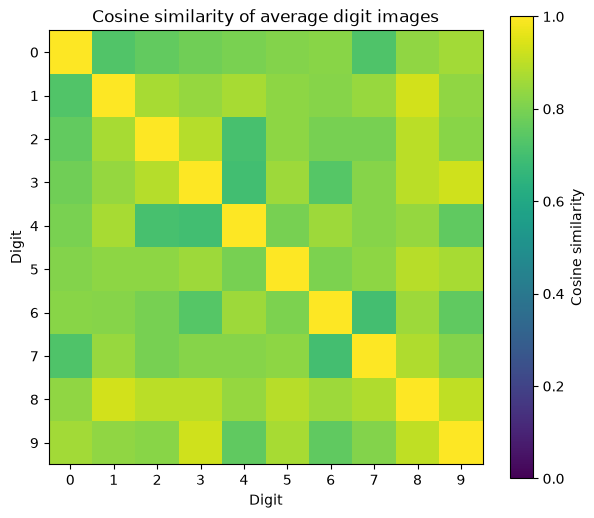

1 and 8: 0.933
3 and 9: 0.927
8 and 9: 0.904
3 and 8: 0.898
2 and 8: 0.898
5 and 8: 0.894
2 and 3: 0.888
7 and 8: 0.882
1 and 4: 0.871
1 and 2: 0.869
8 and 1: 0.933


In [10]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

digits = load_digits()
X, y = digits.data, digits.target
M = np.stack([X[y == d].mean(axis=0) for d in range(10)])
M_unit = M / np.linalg.norm(M, axis=1, keepdims=True)
similarities = M_unit @ M_unit.T
assert M.shape == (10, 64)
assert similarities.shape == (10, 10)

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(similarities, cmap="viridis", vmin=0, vmax=1)
ax.set(xticks=range(10), yticks=range(10), xlabel="Digit", ylabel="Digit",
       title="Cosine similarity of average digit images")
fig.colorbar(image, ax=ax, label="Cosine similarity")
plt.show()

different_digits = np.triu(np.ones(similarities.shape, dtype=bool), k=1)
pairs = np.argwhere(different_digits)
top_pairs = pairs[np.argsort(similarities[different_digits])[::-1][:10]]
for i, j in top_pairs:
    print(f"{i} and {j}: {similarities[i, j]:.3f}")
print(f"8 and 1: {similarities[8, 1]:.3f}")

## Matrix Multiplication 

In [11]:
# Version 1: three nested loops.
def matmul_v1(A, B):
    m, n = A.shape
    n2, p = B.shape
    assert n == n2, f"inner dimensions don't match: A has {n} columns but B has {n2} rows"
    C = np.zeros((m, p))
    for i in range(m):
        for j in range(p):
            for k in range(n):
                C[i, j] += A[i, k] * B[k, j]
    return C

In [12]:
# Version 2: two loops, using the dot product from above.
def matmul_v2(A, B):
    m, n = A.shape
    n2, p = B.shape
    assert n == n2, f"inner dimensions don't match: A has {n} columns but B has {n2} rows"
    C = np.zeros((m, p))
    for i in range(m):
        for j in range(p):
            C[i, j] = dot(A[i, :], B[:, j])
    return C

In [13]:
# Version 3: NumPy's optimized matrix multiplication.
def matmul_v3(A, B):
    return A @ B

# Small example: all three versions should produce [[4, 5], [10, 11]].
A_example = np.array([[1, 2], [3, 4]])
B_example = np.array([[2, 1], [1, 2]])
expected = np.array([[4, 5], [10, 11]])
for matmul in (matmul_v1, matmul_v2, matmul_v3):
    result = matmul(A_example, B_example)
    print(result.tolist())
    assert np.array_equal(result, expected)

# Compare all versions on the requested random matrix shapes.
rng = np.random.default_rng(42)
A_random = rng.random((50, 64))
B_random = rng.random((64, 30))
results = [matmul(A_random, B_random) for matmul in (matmul_v1, matmul_v2, matmul_v3)]
assert np.allclose(results[0], results[1])
assert np.allclose(results[0], results[2])
print("Random-matrix results agree within np.allclose.")

# Prediction: NumPy (@) will be fastest by a wide margin; the triple-loop
# version should beat the dot-in-a-loop version, which slices and calls dot repeatedly.
# Timing (fastest to slowest) prediction: v3, v1, v2.
%timeit matmul_v1(A_random, B_random)
%timeit matmul_v2(A_random, B_random)
%timeit matmul_v3(A_random, B_random)

# Deliberately pass incompatible shapes; check that v1's assertion is clear.
try:
    matmul_v1(np.ones((2, 3)), np.ones((2, 3)))
except AssertionError as error:
    print(f"Caught expected shape error: {error}")
else:
    raise AssertionError("matmul_v1 should reject incompatible matrix shapes")

[[4.0, 5.0], [10.0, 11.0]]
[[4.0, 5.0], [10.0, 11.0]]
[[4, 5], [10, 11]]
Random-matrix results agree within np.allclose.
46.6 ms ± 1.68 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)
22.9 ms ± 964 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)
9.18 μs ± 363 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)
Caught expected shape error: inner dimensions don't match: A has 3 columns but B has 2 rows


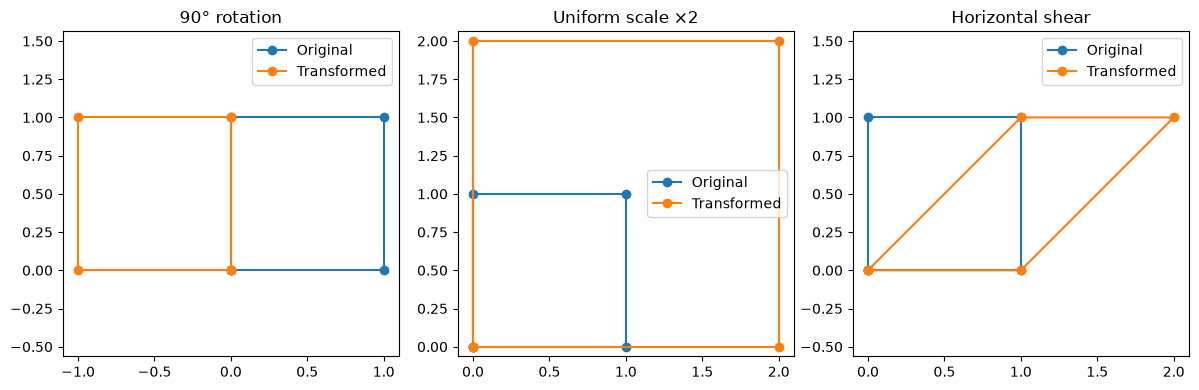

rotation: norms before=(0.664460, 0.596331), after=(0.664460, 0.596331); dot before=0.320699, after=0.320699
scale: norms before=(0.664460, 0.596331), after=(1.328919, 1.192662); dot before=0.320699, after=1.282795


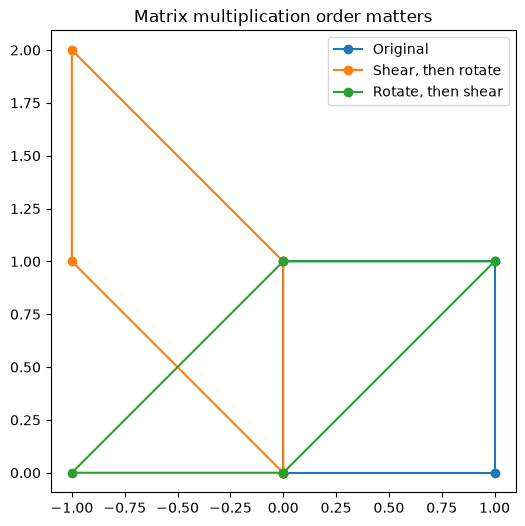

In [14]:
square = np.array([[0, 0], [1, 0], [1, 1], [0, 1], [0, 0]]).T   # shape (2, 5): one column per point

# Three linear transformations: a 90-degree counterclockwise rotation,
# uniform scaling by 2, and a horizontal shear.
rotate = np.array([[0, -1], [1, 0]])
scale = np.array([[2, 0], [0, 2]])
shear = np.array([[1, 1], [0, 1]])

# B1: Predict from the columns rule before looking at each plot.
# Rotation: each point column turns 90 degrees counterclockwise.
# Scale: each point column doubles its distance from the origin.
# Shear: x gains y while y stays fixed, so the square slants right.
transformations = [("90° rotation", rotate), ("Uniform scale ×2", scale), ("Horizontal shear", shear)]
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (name, matrix) in zip(axes, transformations):
    transformed = matrix @ square
    ax.plot(square[0], square[1], "o-", label="Original")
    ax.plot(transformed[0], transformed[1], "o-", label="Transformed")
    ax.set_title(name)
    ax.axis("equal")
    ax.legend()
plt.tight_layout()
plt.show()

# B2: Predict first: rotation preserves each norm and the dot product;
# uniform scale by 2 doubles each norm and multiplies the dot product by 4.
rng = np.random.default_rng(2026)
a = rng.random(2)
b = rng.random(2)
for name, matrix in (("rotation", rotate), ("scale", scale)):
    a_transformed = matrix @ a
    b_transformed = matrix @ b
    norm_a_before, norm_b_before = np.linalg.norm(a), np.linalg.norm(b)
    dot_before = np.dot(a, b)
    norm_a_after = np.linalg.norm(a_transformed)
    norm_b_after = np.linalg.norm(b_transformed)
    dot_after = np.dot(a_transformed, b_transformed)
    print(f"{name}: norms before=({norm_a_before:.6f}, {norm_b_before:.6f}), "
          f"after=({norm_a_after:.6f}, {norm_b_after:.6f}); "
          f"dot before={dot_before:.6f}, after={dot_after:.6f}")
    if name == "rotation":
        assert np.allclose([norm_a_after, norm_b_after], [norm_a_before, norm_b_before])
        assert np.isclose(dot_after, dot_before)
    else:
        assert np.allclose([norm_a_after, norm_b_after], 2 * np.array([norm_a_before, norm_b_before]))
        assert np.isclose(dot_after, 4 * dot_before)

# A rotation preserves lengths and angles because its matrix is orthogonal;
# therefore a·b = ||a|| ||b|| cos(theta) is preserved too. Uniform scaling
# preserves angles, but changes lengths and dot products.

# B3: Predict first: shear then rotate is not the same as rotate then shear.
# With column vectors, the rightmost matrix acts first in each product.
shear_then_rotate = rotate @ shear @ square
rotate_then_shear = shear @ rotate @ square
assert not np.allclose(shear_then_rotate, rotate_then_shear)
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(square[0], square[1], "o-", label="Original")
ax.plot(shear_then_rotate[0], shear_then_rotate[1], "o-", label="Shear, then rotate")
ax.plot(rotate_then_shear[0], rotate_then_shear[1], "o-", label="Rotate, then shear")
ax.set_title("Matrix multiplication order matters")
ax.axis("equal")
ax.legend()
plt.show()

In [ ]:
# Art C: vectorized cosine similarity search over the digits dataset.
from collections import Counter
from sklearn.model_selection import train_test_split

digits = load_digits()  # images: (1797, 8, 8), targets: (1797,)
X, y = digits.data, digits.target  # X: (1797, 64), y: (1797,)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)  # X_train: (1437, 64), X_test: (360, 64); labels: (1437,), (360,)

# C1: Normalize rows independently; input and output both have shape (n_rows, n_features).
def normalize_rows(X):
    norms = np.linalg.norm(X, axis=1, keepdims=True)  # (n_rows, 1)
    if np.any(norms == 0):
        raise ValueError("cannot normalize a zero-length row")
    return X / norms  # (n_rows, n_features)

def cosine_search(queries, database, top_k=5):
    if queries.ndim != 2 or database.ndim != 2:
        raise ValueError("queries and database must be 2-D arrays")
    if queries.shape[1] != database.shape[1]:
        raise ValueError("queries and database must have the same number of features")
    if not 1 <= top_k <= database.shape[0]:
        raise ValueError("top_k must be between 1 and the number of database rows")
    queries_unit = normalize_rows(queries)  # (n_queries, n_features)
    database_unit = normalize_rows(database)  # (n_database, n_features)
    S = queries_unit @ database_unit.T  # (n_queries, n_database)
    candidates = np.argpartition(S, -top_k, axis=1)[:, -top_k:]  # (n_queries, top_k), unordered top indices
    rows = np.arange(S.shape[0])[:, None]  # (n_queries, 1)
    order = np.argsort(S[rows, candidates], axis=1)[:, ::-1]  # (n_queries, top_k), descending-similarity order
    top_indices = np.take_along_axis(candidates, order, axis=1)  # (n_queries, top_k), most similar first
    return top_indices, S  # ((n_queries, top_k), (n_queries, n_database))

top_indices, similarities = cosine_search(X_test, X_train, top_k=5)  # (360, 5), (360, 1437)
assert top_indices.shape == (len(X_test), 5)
assert similarities.shape == (len(X_test), len(X_train))

# C2: Predict before viewing: the five nearest training examples should usually
# share the query digit, though ambiguous handwriting can produce other labels.
fig, axes = plt.subplots(3, 6, figsize=(12, 6))  # axes: (3, 6)
for query_row, ax_row in enumerate(axes):
    ax = ax_row[0]  # one query axis
    ax.imshow(X_test[query_row].reshape(8, 8), cmap="gray_r")  # image: (8, 8)
    ax.set_title(f"Query: {y_test[query_row]}")
    ax.axis("off")
    for rank, (neighbor_index, neighbor_ax) in enumerate(zip(top_indices[query_row], ax_row[1:]), start=1):
        neighbor_ax.imshow(X_train[neighbor_index].reshape(8, 8), cmap="gray_r")  # image: (8, 8)
        score = similarities[query_row, neighbor_index]  # scalar cosine similarity
        neighbor_ax.set_title(f"#{rank}: {y_train[neighbor_index]} ({score:.2f})")
        neighbor_ax.axis("off")
    labels = y_train[top_indices[query_row]]  # (5,)
    print(f"Query label {y_test[query_row]}: neighbor labels {labels.tolist()}; "
          f"all same digit: {np.all(labels == y_test[query_row])}")
fig.suptitle("Cosine-similarity search: each query and its 5 nearest training images")
plt.tight_layout()
plt.show()

# C3: Vote among the top-k labels, using the same Counter tie behavior as Week 1.
cosine_predictions = {}  # k -> predictions with shape (360,)
for k in (1, 3, 5):
    predictions = np.array([
        Counter(y_train[top_indices[row, :k]]).most_common(1)[0][0]
        for row in range(len(X_test))
    ])  # (360,)
    cosine_predictions[k] = predictions

# Recompute Week 1's L2 baseline on the same split for a direct comparison.
X_test_squared = np.sum(X_test ** 2, axis=1, keepdims=True)  # (360, 1)
X_train_squared = np.sum(X_train ** 2, axis=1)  # (1437,)
cross_products = X_test @ X_train.T  # (360, 1437)
squared_distances = np.maximum(X_test_squared + X_train_squared - 2 * cross_products, 0)  # (360, 1437)
l2_indices = np.argpartition(squared_distances, kth=4, axis=1)[:, :5]  # (360, 5), five nearest (unordered)
l2_predictions = {}  # k -> predictions with shape (360,)
for k in (1, 3, 5):
    predictions = np.array([
        Counter(y_train[l2_indices[row, :k]]).most_common(1)[0][0]
        for row in range(len(X_test))
    ])  # (360,)
    l2_predictions[k] = predictions

week1_reported = {1: 0.9861, 3: 0.9861, 5: 0.9833}  # reported Week 1 accuracies
print("k | Week 1 L2 | L2 rerun | Cosine | Cosine vs Week 1 (image equivalents)")
for k in (1, 3, 5):
    l2_accuracy = np.mean(l2_predictions[k] == y_test)  # scalar
    cosine_accuracy = np.mean(cosine_predictions[k] == y_test)  # scalar
    image_difference = round((cosine_accuracy - week1_reported[k]) * len(y_test))  # scalar images
    print(f"{k} | {week1_reported[k]:.4f} | {l2_accuracy:.4f} | {cosine_accuracy:.4f} | {image_difference:+d}")

# Here k=1 gains one correct image (1/360 ~= 0.28 percentage points); k=3 and
# k=5 match the reported L2 results. One image is too small to claim a robust
# advantage; it may just reflect the particular test split/noisy handwriting.
# A pixel vector's length roughly tracks total ink/intensity. Ignoring length
# can help when the same digit is written darker or thicker, but can hurt when
# ink amount or stroke intensity carries useful information about the image.